# EDA: what is associated with Netflix TV series popularity

Cleaning is in `src/tmdb_tv_shows/clean.py`, the reasons are in `tmdb.ipynb`. This notebook only explores. **Assumed** means not verified.

`netflix` = shows where Netflix is in `networks` **or** the `homepage` is on netflix.com (2,031 shows).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tmdb_tv_shows.clean import build

raw, clean, dedup, dropped = build()
netflix = dedup[dedup.is_netflix].copy()
print(len(dedup), len(netflix))   # 164705 2031

SNAPSHOT = pd.Timestamp("2024-04-04")   # latest last_air_date in the data, assumed capture date


164705 2031


In [2]:
# Chart theme: Sky deck template (Arial, cream surface, Sky blue). Netflix red is used only for Netflix.
# Checked with the dataviz validator on the cream surface: blue alone, and Netflix red against the muted grey, both pass
# (the grey is deliberately neutral, so it fails the "chroma floor" check meant for categorical colours).
SURFACE, TITLE, INK, MUTED, GRID = "#F0EAD6", "#0C1B87", "#0B1226", "#5B6B84", "#DCE3EC"
BLUE = "#0072C9"          # Sky accent 1: single series
NETFLIX_RED = "#C4101C"   # Netflix entity colour (slightly darker than brand #E50914, solid fills looked too bright)
OTHER = MUTED             # every other network or group

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": TITLE, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "x", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False,
})


## 1. Data quality

Checks on the 2,031 Netflix shows: missing data, flags and zeros, columns, Netflix coverage, outliers, then a summary.

### Missing data

- `tagline` 80.9% missing. A marketing slogan, **assumed** weak from domain knowledge. Not used.
- `created_by` 45.6% missing. Interesting, but imputing creators is not feasible. No imputation.
- Usable with a missing-value approach: `episode_run_time` 28.6%, `production_companies` 27.4%, `production_countries` 12.3%, `vote_average` 12.1% (no votes).
- `networks` is 2.0% missing, the homepage-only shows with a blank `networks`.
- The table below also lists our added columns, so some rows repeat (`genres` and `genres_list`).

In [3]:
cols = list(netflix.columns)
missing = netflix[cols].isna().agg(["sum", "mean"]).T
missing["mean"] = (missing["mean"] * 100).round(1)
missing.sort_values("mean", ascending=False)

,sum,mean
tagline,1643.0,80.9
created_by,926.0,45.6
created_by_list,926.0,45.6
episode_run_time,580.0,28.6
production_companies_list,556.0,27.4
production_companies,556.0,27.4
production_countries,250.0,12.3
vote_average,246.0,12.1
last_air_date,210.0,10.3
homepage,186.0,9.2


### Flags and zeros

- `dates_reversed` and `votes_inconsistent` are 0 in Netflix.
- 246 shows have 0 votes, so `vote_average` is missing. 548 have 5 or fewer votes.
- `popularity` is 0 for 4 shows, the smallest positive value is 0.6.
- 153 shows have no `first_air_date` and 4 start after 2024-04-04 (157 not launched by date).

In [4]:
print(netflix.dates_reversed.sum(), netflix.votes_inconsistent.sum())               # 0 0
print((netflix.vote_count == 0).sum(), (netflix.vote_count <= 5).sum())            # 246 548
print((netflix.popularity == 0).sum(), netflix.popularity[netflix.popularity > 0].min())   # 4 0.6
print(netflix.first_air_date.isna().sum(), (netflix.first_air_date > "2024-04-04").sum())  # 153 4

0 0
246 548
4 0.6
153 4


### Columns with little information or overlap

- `in_production` repeats `status` exactly.
- `adult` is True for 3 shows, almost constant.
- `type` has 5 values (Scripted, Miniseries, Reality, Documentary, Talk Show), usable. **Assumed** known before launch.
- `original_language` equals the first of `languages` in about 91% of shows, so they overlap.

In [5]:
orig = list(raw.columns)
print(netflix[orig].astype(str).nunique().sort_values().head(8))
print(netflix.adult.value_counts())   # False 2028, True 3
print(netflix.type.value_counts())
print(pd.crosstab(netflix.status, netflix.in_production))
print((netflix.original_language == netflix.languages.str.split(", ").str[0]).mean())

in_production         2
adult                 2
status                5
type                  5
number_of_seasons    13
original_language    34
origin_country       81
episode_run_time     90
dtype: int64
adult
False    2028
True        3
Name: count, dtype: int64
type
Scripted       1165
Miniseries      447
Reality         212
Documentary     185
Talk Show        22
Name: count, dtype: int64
in_production     False  True 
status                        
Canceled            213      0
Ended              1009      0
In Production         0    151
Planned               0     42
Returning Series      0    616
0.913343180699163


### Netflix coverage

- TMDB's guideline says `networks` typically lists only the first network to air a show, so licensed shows (Friends on NBC) list their original network.
- 1,929 shows match by network, 1,718 by netflix.com homepage, 1,616 both. 102 are homepage only: 41 with blank `networks`, 61 with other networks.
- Among the network matches, 181 list other networks too (YouTube, Channel 3 and others).
- `networks` is never changed. The homepage match is its own column.

In [6]:
print(netflix.netflix_network.sum(), netflix.netflix_homepage.sum(),
      (netflix.netflix_network & netflix.netflix_homepage).sum())     # 1929 1718 1616
h = netflix[~netflix.netflix_network & netflix.netflix_homepage]
print(len(h), h.networks.isna().sum(), h.networks.notna().sum())      # 102 41 61
nn = netflix[netflix.netflix_network]
k = nn.networks_list.apply(len)
print((k == 1).sum(), (k > 1).sum())                                  # 1748 181
h[h.networks.notna()][["name", "networks"]].head()

1929 1718 1616
102 41 61
1748 181


,name,networks
27,Friends,NBC
3725,Top Boy,Channel 4
6894,Rabbids Invasion,"France 3, Nicktoons"
12009,Some Assembly Required,YTV
5379,Historia de un clan,Telefe


### Outliers

- Seasons (max 30) and episodes (max 973) are long-running shows, genuine. Power Rangers, Pen Tor (817), Bakugan, Friends.
- `episode_run_time` max 515 (Tunnel, 16 episodes). The largest look like total runtimes, not per episode. **Assumed**, not proven. None above 600.
- Votes and popularity are very skewed but real (Money Heist 17,836 votes, Sex Education popularity 1,009).
- Kept everything. Use log scales or medians in EDA.

In [7]:
num = ["number_of_seasons", "number_of_episodes", "episode_run_time", "vote_count", "popularity"]
print(netflix[num].describe(percentiles=[.5, .9, .99]).round(1).T)
big = netflix.nlargest(5, "episode_run_time")[["name", "number_of_episodes", "episode_run_time"]]
big.assign(per_episode=big.episode_run_time / big.number_of_episodes)

                     count   mean    std  min   50%    90%     99%      max
number_of_seasons   2031.0    1.6    1.5  1.0   1.0    3.0     7.0     30.0
number_of_episodes  2029.0   15.2   34.2  0.0   8.0   32.0    92.4    973.0
episode_run_time    1451.0   41.0   25.4  3.0  41.0   60.0   107.5    515.0
vote_count          2031.0  191.7  891.0  0.0  20.0  313.0  2799.2  17836.0
popularity          2031.0   15.6   40.8  0.0   6.5   31.7   144.1   1009.0


,name,number_of_episodes,episode_run_time,per_episode
41246,Tunnel,16.0,515.0,32.1875
2687,The One,8.0,337.0,42.1250
5184,The Innocent Man,6.0,288.0,48.0000
36408,Sunshine Eyes,10.0,275.0,27.5000
5569,The Pharmacist,4.0,217.0,54.2500


### Data quality summary

- **Complete or nearly:** `id`, `name`, `type`, `status`, `popularity`, `vote_count`, `original_language`, `number_of_seasons`, plus `genres`, `origin_country`, `languages`, `overview` (each under 4% missing).
- **Usable with a missing-value approach:** `episode_run_time`, `production_companies`, `production_countries`, `vote_average`.
- **Weak or not used:** `tagline`, `created_by`, `in_production`, `adult`, links and images.
- **Cautions:** popularity is one noisy snapshot, `vote_average` is unreliable for few votes, some runtimes may be totals, the Netflix label depends on `networks` plus homepage, the snapshot date (2024-04-04) is inferred, 157 shows are not launched by date.

### How sparse is the data? Netflix vs all shows

- Share of shows with no usable value per column, for the Netflix subset and for all shows (one row per show after cleaning). Original 29 columns only.
- `vote_count` is never missing, but a 0 means no votes recorded, so it is drawn hatched.


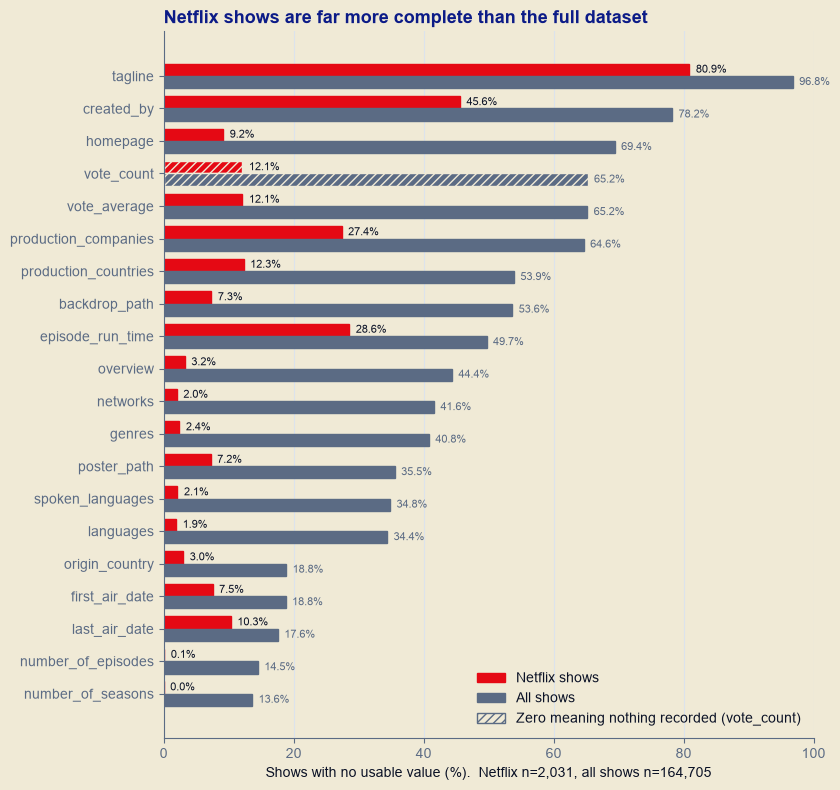

In [8]:
from matplotlib.patches import Patch

orig = list(raw.columns)

def gaps(df):
    pct = df[orig].isna().mean() * 100
    pct["vote_count"] = (df.vote_count == 0).mean() * 100     # zero = no votes recorded
    return pct

tbl = pd.DataFrame({"netflix": gaps(netflix), "all": gaps(dedup)})
tbl = tbl[tbl.max(axis=1) >= 0.05]                            # drop columns that are complete in both
tbl = tbl.loc[tbl.max(axis=1).sort_values().index]

NET, ALL = NETFLIX_RED, OTHER
fig, ax = plt.subplots(figsize=(8.5, 8))
y = np.arange(len(tbl)); h = 0.38
for i, (name, row) in enumerate(tbl.iterrows()):
    hatch = "////" if name == "vote_count" else None
    ax.barh(i + h/2, row["netflix"], height=h, color=NET, hatch=hatch, edgecolor=SURFACE if hatch else NET)
    ax.barh(i - h/2, row["all"], height=h, color=ALL, hatch=hatch, edgecolor=SURFACE if hatch else ALL)
    ax.text(row["netflix"] + 1, i + h/2, f"{row['netflix']:.1f}%", va="center", fontsize=8)
    ax.text(row["all"] + 1, i - h/2, f"{row['all']:.1f}%", va="center", fontsize=8, color=MUTED)
ax.set_yticks(y); ax.set_yticklabels(tbl.index)
ax.set_xlim(0, 100)
ax.set_xlabel(f"Shows with no usable value (%).  Netflix n={len(netflix):,}, all shows n={len(dedup):,}")
ax.set_title("Netflix shows are far more complete than the full dataset")
ax.legend(handles=[Patch(color=NET, label="Netflix shows"), Patch(color=ALL, label="All shows"),
                   Patch(facecolor=SURFACE, edgecolor=MUTED, hatch="////", label="Zero meaning nothing recorded (vote_count)")],
          frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../docs/data_sparsity_compare.png", dpi=150, bbox_inches="tight")   # for the slide, docs/ is git-ignored
plt.show()


**Finding:**
- Netflix shows are far more complete than the full dataset. Netflix vs all: `overview` 3.2% vs 44.4%, `genres` 2.4% vs 40.8%, `networks` 2.0% vs 41.6%, `homepage` 9.2% vs 69.4%, `vote_count` zero 12.1% vs 65.2%, `created_by` 45.6% vs 78.2%.
- `tagline` (80.9% vs 96.8%) and `created_by` are sparse in both. The smallest gaps are `last_air_date` and `episode_run_time`.
- **Caveats:** `networks` and `homepage` look more complete for Netflix partly by construction, because the Netflix label uses them. **Assumed:** Netflix titles are well known, so their TMDB pages are fuller. Netflix results may not carry over to obscure shows.


## 2. Is Netflix the main competitor?

- Launched shows in the full dataset (one row per show), grouped by network. A show with several networks counts under each. Shows not launched by the snapshot are left out for every network, so Netflix is 1,874 here, not 2,031.
- Netflix here uses the same rule as the rest of the notebook: Netflix in `networks` **or** a netflix.com homepage. This adds 101 launched shows whose `networks` does not say Netflix, through a new column (`networks` itself is not changed).
- Other networks get no equivalent homepage rule (it is built for Netflix only), so Netflix is slightly favoured in these counts. A fairer all-networks version is a next-time item.
- TMDB's guideline says `networks` usually lists only the first network, so licensed shows count under their original network (**assumed**).
- Two questions: who has the most shows, and who has the highest median popularity.


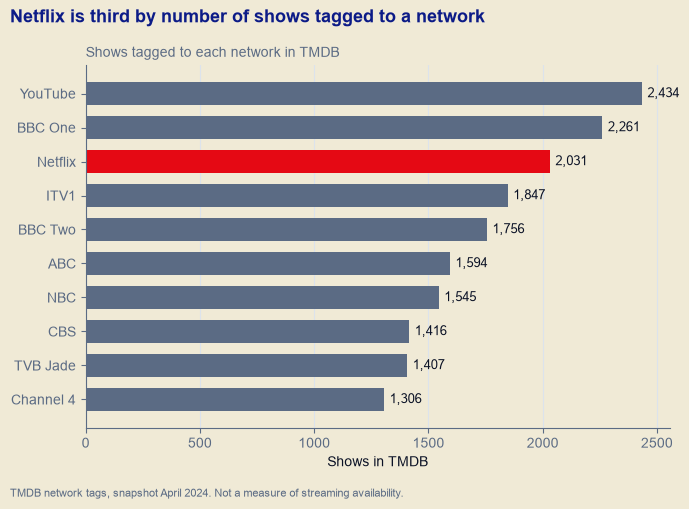

In [9]:
allshows = dedup.copy()          # every show, including those with no first air date
allshows["log_pop"] = np.log1p(allshows.popularity)

# networks plus the homepage rule: a show on netflix.com counts under Netflix even if `networks` does not say so
# (`networks` itself is not changed, this is a new column)
add_netflix = allshows.is_netflix & ~allshows.netflix_network
allshows["networks_x"] = [(n if isinstance(n, list) else []) + (["Netflix"] if a else [])
                          for n, a in zip(allshows.networks_list, add_netflix)]

# launch-year analysis below needs a first air date (not after the snapshot), so use this subset
d = allshows[allshows.first_air_date.notna() & (allshows.first_air_date <= SNAPSHOT)].copy()
d["launch_year"] = d.first_air_date.dt.year

def by_network(df):
    e = df.explode("networks_x").dropna(subset=["networks_x"])     # a show counts under each network
    t = e.groupby("networks_x").agg(n=("id", "size"), median_pop=("popularity", "median"),
                                       median_log=("log_pop", "median"))
    return t, e

NET = NETFLIX_RED          # Netflix red, every other network in the theme grey (OTHER)
colour = lambda names: [NET if n == "Netflix" else OTHER for n in names]

# chart 1: who has the most shows tagged to each network (every show, dated or not)
t, _ = by_network(allshows)
top = t.sort_values("n").tail(10)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.n, color=colour(top.index), height=0.7)
for i, v in enumerate(top.n):
    ax.text(v + top.n.max() * 0.01, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Shows tagged to each network in TMDB", loc="left", fontsize=10, fontweight="normal", color=MUTED)
ax.set_xlabel("Shows in TMDB")
ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Netflix is third by number of shows tagged to a network", x=0.02, ha="left", fontsize=13, fontweight="bold", color=TITLE)
fig.text(0.02, 0.005, "TMDB network tags, snapshot April 2024. Not a measure of streaming availability.", fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("../docs/networks_most_shows.png", dpi=150, bbox_inches="tight")
plt.show()


### Popularity of the biggest networks

- A median over only a few shows is noisy, and the highest medians in the full table belong to small or niche networks (for example Cartoon Network, Univision). So compare the 12 networks with the most shows since 2016.
- Dot is the median, line is the 95% bootstrap range.


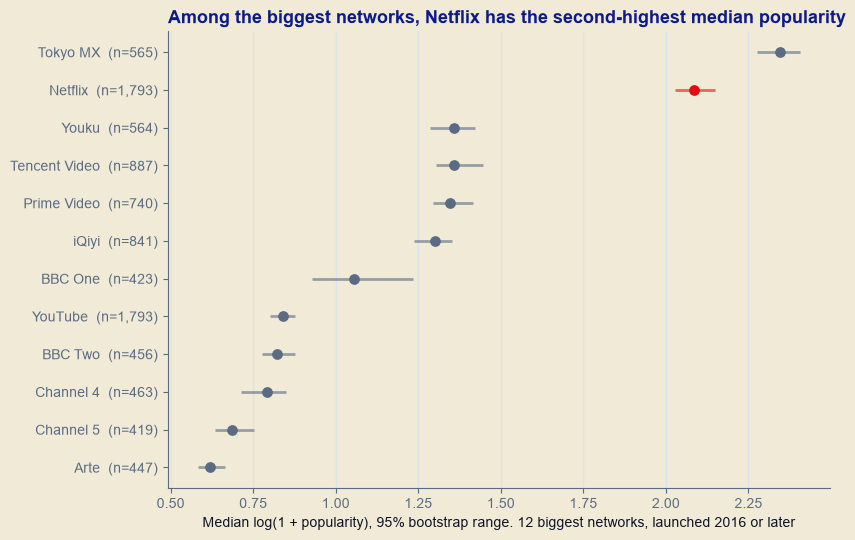

,n,median_pop,median_log,lo,hi
networks_x,,,,,
Tokyo MX,565,9.43,2.34,2.28,2.41
Netflix,1793,7.05,2.09,2.03,2.15
Youku,564,2.89,1.36,1.28,1.42
Tencent Video,887,2.88,1.36,1.30,1.45
Prime Video,740,2.84,1.34,1.29,1.42
iQiyi,841,2.67,1.30,1.24,1.35
BBC One,423,1.88,1.06,0.93,1.23
YouTube,1793,1.32,0.84,0.80,0.88
BBC Two,456,1.27,0.82,0.78,0.88


In [10]:
# chart 2: popularity of the 12 biggest networks since 2016 (median, 95% bootstrap range)
r = d[d.launch_year >= 2016]
t, e = by_network(r)
big = t.sort_values("n").tail(12).index
rng = np.random.default_rng(0)

def boot_range(s, k=1000):
    s = s.to_numpy()
    m = [np.median(rng.choice(s, len(s))) for _ in range(k)]
    return np.percentile(m, 2.5), np.percentile(m, 97.5)

res = t.loc[big].copy()
res[["lo", "hi"]] = [boot_range(e[e.networks_x == n].log_pop) for n in big]
res = res.sort_values("median_log")

y = np.arange(len(res))
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, (name, row) in enumerate(res.iterrows()):
    c = NET if name == "Netflix" else OTHER
    ax.hlines(i, row.lo, row.hi, color=c, lw=2, alpha=0.6)
    ax.scatter(row.median_log, i, color=c, s=45, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([f"{n}  (n={k:,})" for n, k in zip(res.index, res.n)])
ax.set_xlabel("Median log(1 + popularity), 95% bootstrap range. 12 biggest networks, launched 2016 or later")
ax.set_title("Among the biggest networks, Netflix has the second-highest median popularity")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../docs/networks_popularity.png", dpi=150, bbox_inches="tight")
plt.show()

res.sort_values("median_log", ascending=False).round(2)


**Finding:**
- **Most shows:** Netflix is third across all years (1,874, behind YouTube 2,345 and BBC One 2,029) and level with YouTube since 2016 (1,793 each). It has about twice as many as the next streamer (Tencent Video 887, iQiyi 841, Prime Video 740).
- **Popularity:** among the 12 networks with the most shows since 2016, Netflix has the second-highest median (2.09, about 7.1), after Tokyo MX (2.34, about 9.4). The ranges do not overlap. Netflix is well above Prime Video (1.34), Youku, Tencent Video and iQiyi (about 1.3 to 1.4).
- Across all networks with 50 or more shows (all years) Netflix ranks 39th of 384 by median, because small children's, Spanish-language and niche networks have higher medians. Apple TV+ (12.8, 136 shows) is above Netflix.
- **Share of all popularity:** Netflix holds 3.3% over all years (fourth, behind CBS 6.0%, NBC 5.3% and ABC 4.2%), and 7.5% of the popularity of shows launched since 2016, the largest of any network (next is Tokyo MX at 2.9%).
- **Reading:** a reasonable case for Netflix as the main competitor among streamers (the most recent shows, the largest share of recent attention, high popularity), but it is not the top on any single measure. This is supporting evidence. The brief already frames the data around Netflix.
- **Caveats:** `networks` is mostly the first network. One snapshot of TMDB attention, not subscribers, spend or viewing. Medians for small networks are noisy. YouTube is mostly small creator content. The homepage rule is applied to Netflix only. **Assumed:** TMDB's audience may favour some regions.


### Share of popularity

- Popularity added up over each network's shows, as a share of all popularity. Only the 96,249 shows that have a network are counted (the other 42% have none), and a show is counted once in each of its networks. Each network's share of shows is next to it, so a network above its share of shows holds more attention than its size suggests.


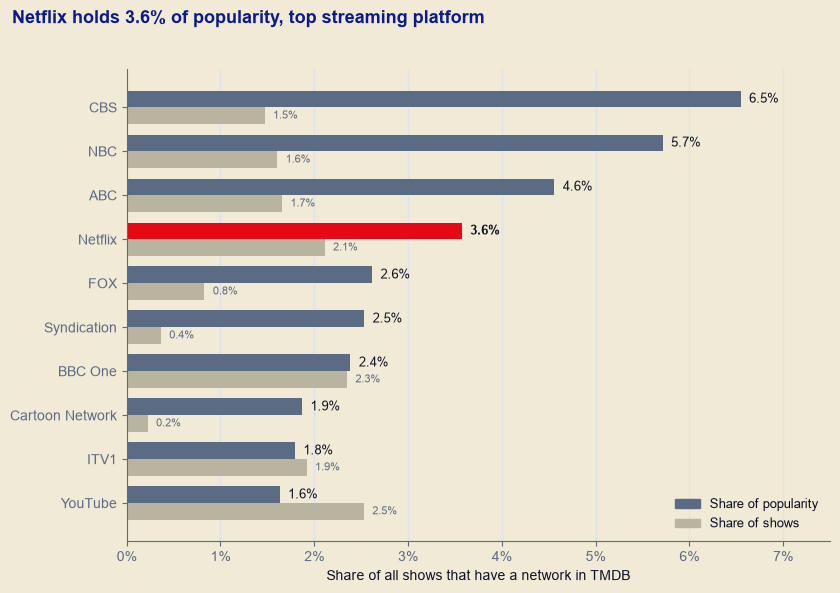

,n,sh_shows,sh_pop,ratio
networks_x,,,,
CBS,1415,0.015,0.065,4.454
NBC,1545,0.016,0.057,3.561
ABC,1594,0.017,0.046,2.754
Netflix,2031,0.021,0.036,1.693
FOX,798,0.008,0.026,3.155
Syndication,350,0.004,0.025,6.964
BBC One,2261,0.023,0.024,1.015
Cartoon Network,215,0.002,0.019,8.370
ITV1,1847,0.019,0.018,0.935


In [11]:
# chart 3: share of popularity vs share of shows (a show counts once in each of its networks)
import matplotlib.ticker as mt
from matplotlib.patches import Patch

has_net = allshows[allshows.networks_x.map(len) > 0]
share = has_net.explode("networks_x").groupby("networks_x").agg(n=("id", "nunique"), pop=("popularity", "sum"))
share["sh_shows"] = share.n / len(has_net)
share["sh_pop"] = share["pop"] / has_net.popularity.sum()
SHOWS_COL = "#B9B49F"       # lighter neutral for "share of shows" (the theme grey is used for share of popularity)

def share_chart(tbl, title, note, fname, xmax, figh):
    tbl = tbl.iloc[::-1]
    h = 0.38
    fig, ax = plt.subplots(figsize=(8.5, figh))
    for i, (name, row) in enumerate(tbl.iterrows()):
        nf = name == "Netflix"
        ax.barh(i + h / 2, row.sh_pop, height=h, color=NETFLIX_RED if nf else MUTED)
        ax.barh(i - h / 2, row.sh_shows, height=h, color=SHOWS_COL)
        ax.text(row.sh_pop + xmax * 0.012, i + h / 2, f"{row.sh_pop:.1%}", va="center", fontsize=9, fontweight="bold" if nf else "normal")
        ax.text(row.sh_shows + xmax * 0.012, i - h / 2, f"{row.sh_shows:.1%}", va="center", fontsize=8, color=MUTED)
    ax.set_yticks(range(len(tbl))); ax.set_yticklabels(tbl.index)
    ax.set_xlim(0, xmax)
    ax.set_xticks(np.arange(0, xmax, 0.01)); ax.xaxis.set_major_formatter(mt.PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("Share of all shows that have a network in TMDB")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(handles=[Patch(color=MUTED, label="Share of popularity"), Patch(color=SHOWS_COL, label="Share of shows")], loc="lower right", fontsize=9)
    fig.suptitle(title, x=0.02, ha="left", fontsize=13, fontweight="bold", color=TITLE)
    if note:
        fig.text(0.02, 0.005, note, fontsize=7.5, color=MUTED)
    fig.tight_layout(rect=(0, 0.035 if note else 0, 1, 0.96))
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

top10 = share.sort_values("sh_pop", ascending=False).head(10)
share_chart(top10, "Netflix holds 3.6% of popularity, top streaming platform",
            None,
            "../docs/networks_share_popularity.png", 0.075, 6)
top10[["n", "sh_shows", "sh_pop"]].assign(ratio=top10.sh_pop / top10.sh_shows).round(3)


**Finding:**
- **Share of popularity:** Netflix holds 3.6% of all popularity, fourth behind CBS (6.5%), NBC (5.7%) and ABC (4.6%), from 2.1% of shows. The three ahead are long-running US broadcasters.
- **Against its size:** Netflix holds 1.7 times its share of shows. That gap is smaller than CBS (4.5 times), NBC (3.6), FOX (3.2) and ABC (2.8). So Netflix is among the biggest holders of attention, but it is not the top network on this measure.
- **Caveats:** summed popularity favours networks with many long-running hits. 42% of shows have no network and are not counted. Popularity is a TMDB attention score at the snapshot, not viewing or subscribers, and a network tag is not streaming availability. The data does not say which networks are streaming platforms, so the streamers-only view below uses our own list.


### Share among paid streamers

- The data has no streamer flag, so the list of paid streamers is **our classification (assumed)**, from network names. **Clear:** subscription services such as Netflix, Prime Video, Disney+, HBO Max, Apple TV+, Paramount+. **Borderline:** free, ad-supported or mixed tiers, or cable (Hulu, Peacock, iQiyi, Tencent Video, Youku, HBO, Showtime and others). Spelling variants are merged (for example iQiyi and iQIYI, Max and HBO Max).
- The base is now **unique shows on at least one listed streamer**, so the shares read as a split between streamers. A show on two streamers counts under each, so the shares add up to a little over 100%.
- Shown for the clear plus borderline list. The clear-only numbers are printed under the chart, because the list choice moves Netflix's share a lot.
- `networks_x` already includes the Netflix homepage rule. Other streamers get no equivalent, and TMDB usually lists only the first network, so streamer counts are probably too low (**assumed**).

In [ ]:
# chart 4: share among paid streamers only. The list is our classification (assumed), not a field in the data.
CLEAR = {"Netflix": ["netflix"], "Prime Video": ["prime video"], "Disney+": ["disney+"], "HBO Max": ["hbo max", "max"],
         "Apple TV+": ["apple tv+"], "Paramount+": ["paramount+"], "discovery+": ["discovery+"], "Disney+ Hotstar": ["disney+ hotstar"],
         "Viaplay": ["viaplay"], "Crave": ["crave"], "Showmax": ["showmax"], "Stan": ["stan"], "Starz": ["starz"], "ZEE5": ["zee5"],
         "TVING": ["tving"], "wavve": ["wavve"], "Shudder": ["shudder"], "CuriosityStream": ["curiositystream"]}
BORDER = {"Hulu": ["hulu"], "Peacock": ["peacock"], "iQiyi": ["iqiyi"], "Tencent Video": ["tencent video"], "Youku": ["youku"],
          "WeTV": ["wetv"], "Viki": ["viki"], "Viu": ["viu"], "STAR+": ["star+"], "HBO": ["hbo"], "Showtime": ["showtime"],
          "BBC iPlayer": ["bbc iplayer"], "ITVX": ["itvx"]}

def streamer_table(mapping):
    cn = {v: k for k, vs in mapping.items() for v in vs}            # lower-case spelling variants -> one name
    s = allshows.assign(streamer=[sorted({cn[x.lower()] for x in n if x.lower() in cn}) for n in allshows.networks_x])
    s = s[s.streamer.map(len) > 0]                                   # unique shows on at least one listed streamer
    t = s.explode("streamer").groupby("streamer").agg(n=("id", "size"), pop=("popularity", "sum"))
    t["sh_shows"] = t.n / len(s)
    t["sh_pop"] = t["pop"] / s.popularity.sum()
    return t.sort_values("sh_pop", ascending=False), len(s)

st_clear, n_clear = streamer_table(CLEAR)
st_both, n_both = streamer_table({**CLEAR, **BORDER})
top = st_both.head(10).iloc[::-1]

h = 0.38
fig, ax = plt.subplots(figsize=(8.5, 5.8))
for k, (name, row) in enumerate(top.iterrows()):
    nf = name == "Netflix"
    ax.barh(k + h / 2, row.sh_pop, height=h, color=NETFLIX_RED if nf else MUTED)
    ax.barh(k - h / 2, row.sh_shows, height=h, color=SHOWS_COL)
    ax.text(row.sh_pop + 0.004, k + h / 2, f"{row.sh_pop:.0%}", va="center", fontsize=9, fontweight="bold" if nf else "normal")
    ax.text(row.sh_shows + 0.004, k - h / 2, f"{row.sh_shows:.0%}", va="center", fontsize=8, color=MUTED)
ax.set_yticks(range(len(top))); ax.set_yticklabels([n + ("*" if n in BORDER else "") for n in top.index])
ax.set_xlim(0, 0.36); ax.set_xticks(np.arange(0, 0.35, 0.1)); ax.xaxis.set_major_formatter(mt.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of paid-streamer popularity or shows")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=MUTED, label="Share of popularity"), Patch(color=SHOWS_COL, label="Share of shows")], loc="lower right", fontsize=9, frameon=False)
fig.suptitle("Among paid streamers, Netflix holds 30% of popularity", x=0.02, ha="left", fontsize=13, fontweight="bold", color=TITLE)
fig.text(0.02, 0.005, "Paid streamers by our classification (clear plus borderline, * = borderline). Share among unique streamer shows.", fontsize=7.5, color=MUTED)
fig.tight_layout(rect=(0, 0.035, 1, 0.96))
plt.savefig("../docs/streamers_share_of_streamers.png", dpi=150, bbox_inches="tight")
plt.show()

# how much does the list choice matter? Netflix's share under each list
pd.DataFrame({"unique streamer shows": [n_clear, n_both],
              "Netflix share of popularity": [st_clear.loc["Netflix", "sh_pop"], st_both.loc["Netflix", "sh_pop"]],
              "Netflix share of shows": [st_clear.loc["Netflix", "sh_shows"], st_both.loc["Netflix", "sh_shows"]],
              "next streamer": [st_clear.index[1], st_both.index[1]],
              "next share of popularity": [st_clear.iloc[1].sh_pop, st_both.iloc[1].sh_pop]},
             index=["clear only", "clear plus borderline"]).round(3)

**Finding:**
- **Among paid streamers (our list):** Netflix holds **30%** of popularity from 22% of shows (clear plus borderline, 9,094 unique shows). On the clear list alone it holds **47%** from 39% of shows (5,266 shows). Netflix is the largest on both lists, and about three to four times the next streamer.
- **The next streamers:** clear list, Prime Video 13% and Disney+ 9%. With borderline, HBO 9%, Prime Video 8% and Tencent Video 8%.
- **Against its size:** Netflix holds more popularity than its share of shows on both lists. Prime Video, Tencent Video and iQiyi go the other way, with more shows than popularity.
- **Reading:** supports Netflix as the main competitor among streamers, with the size of the lead depending on the list (30% to 47%), so quote the range.
- **Caveats:** the list is our judgement, not data (**assumed**). HBO and Showtime are cable and sit in the borderline group, and HBO ranks second there. Streamer counts are probably too low, because TMDB usually lists only the first network. Showmax's 3% on the clear list comes from a few popular shows (39), not a large catalogue. Shares add to a little over 100% because shows on two streamers count under each. A TMDB attention score at one snapshot, not subscribers or viewing.

## 3. Scope and target

- **Scope:** launched = `first_air_date` exists and is on or before the snapshot date (2024-04-04). That is 1,874 of the 2,031 Netflix shows.
- **Target view:** popularity is very skewed, so we read it on a log scale, `log_pop = log1p(popularity)`.


In [12]:
# SNAPSHOT (2024-04-04) is set in the setup cell: the latest last_air_date, an assumed capture date

launched = netflix[netflix.first_air_date.notna() & (netflix.first_air_date <= SNAPSHOT)].copy()
print(len(netflix), len(launched))      # expect 2031 1874
launched.status.value_counts()


2031 1874


status
Ended               1009
Returning Series     608
Canceled             212
In Production         44
Planned                1
Name: count, dtype: int64

16.674665421558164 7.3100000000000005


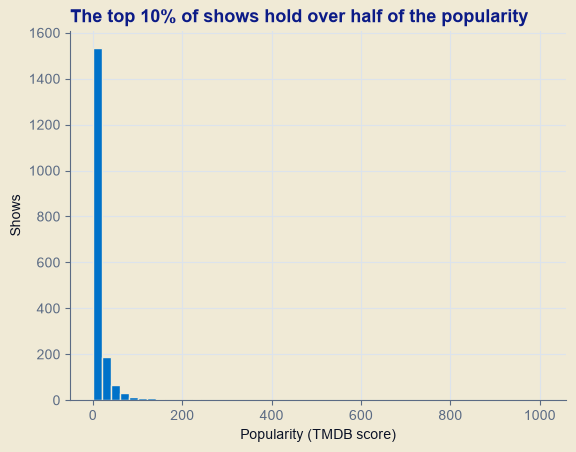

In [13]:
launched.popularity.hist(bins=50, color=BLUE, edgecolor=SURFACE)
plt.title("The top 10% of shows hold over half of the popularity")
plt.xlabel("Popularity (TMDB score)")
plt.ylabel("Shows")
print(launched.popularity.mean(), launched.popularity.median())

2.209027964199965 2.1174594930195036
skew raw: 12.09 | log1p: 0.76


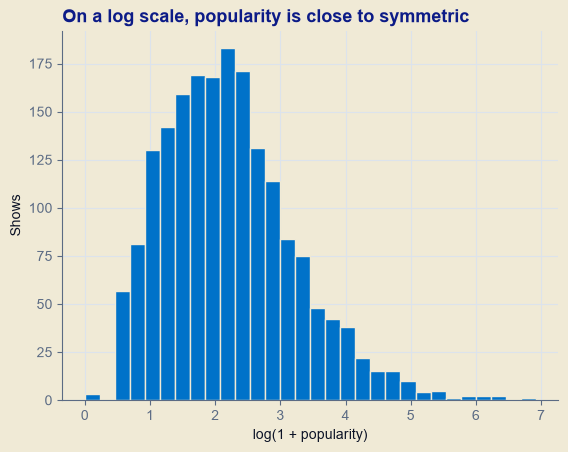

In [14]:
launched["log_pop"] = np.log1p(launched.popularity)

launched.log_pop.hist(bins=30, color=BLUE, edgecolor=SURFACE)
plt.title("On a log scale, popularity is close to symmetric")
plt.xlabel("log(1 + popularity)")
plt.ylabel("Shows")
print(launched.log_pop.mean(), launched.log_pop.median())
print("skew raw:", round(launched.popularity.skew(), 2), "| log1p:", round(launched.log_pop.skew(), 2))

## 4. Patterns and relationships

Launched Netflix shows only (1,874). Popularity is read as `log_pop = log1p(popularity)`, medians not means.

### Popularity by launch year

- Launch years before 2014 have too few shows each, so they are pooled into one bucket (33 shows). 2024 is a partial year.
- The shaded band is the 95% bootstrap range of the median: how much the median would move with a slightly different set of shows.


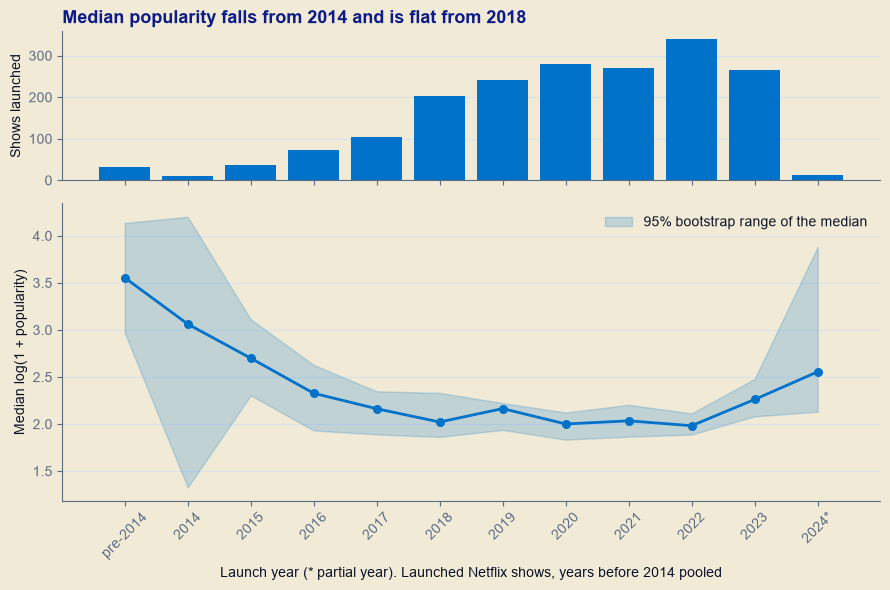

pre-2014: n=33, median=3.55, range 2.97 to 4.14


,n,median_log,lo,hi,overlaps_pre2014
2014,11,3.06,1.33,4.20,True
2015,37,2.70,2.30,3.11,True
2016,74,2.33,1.93,2.63,False
2017,104,2.16,1.89,2.35,False
2018,204,2.02,1.86,2.33,False
2019,241,2.16,1.94,2.22,False
2020,280,2.00,1.83,2.12,False
2021,271,2.03,1.87,2.20,False
2022,341,1.98,1.89,2.11,False
2023,265,2.26,2.08,2.48,False


In [15]:
launched["launch_year"] = launched.first_air_date.dt.year
launched["year_group"] = launched.launch_year.where(launched.launch_year >= 2014, 0)  # 0 = pre-2014

rng = np.random.default_rng(0)

def boot_ci(s, k=1000):
    """95% bootstrap range of the median. NaN if under 3 shows."""
    s = s.to_numpy()
    if len(s) < 3:
        return pd.Series({"lo": np.nan, "hi": np.nan})
    meds = [np.median(rng.choice(s, len(s))) for _ in range(k)]
    return pd.Series({"lo": np.percentile(meds, 2.5), "hi": np.percentile(meds, 97.5)})

g = launched.groupby("year_group")
by_year = g.agg(n=("id", "size"), median_pop=("popularity", "median"),
                median_log=("log_pop", "median"))
by_year = by_year.join(g.log_pop.apply(boot_ci).unstack())
by_year.index = ["pre-2014" if y == 0 else str(int(y)) for y in by_year.index]
by_year.index = [i + "*" if i == "2024" else i for i in by_year.index]   # * = partial year

# chart
x = np.arange(len(by_year))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [1, 2]})

ax1.bar(x, by_year.n, color=BLUE, width=0.8)
ax1.set_ylabel("Shows launched")
ax1.set_title("Median popularity falls from 2014 and is flat from 2018")

ax2.fill_between(x, by_year.lo, by_year.hi, color=BLUE, alpha=0.2,
                 label="95% bootstrap range of the median")
ax2.plot(x, by_year.median_log, color=BLUE, lw=2)
ax2.scatter(x, by_year.median_log, color=BLUE, s=30, zorder=3)
ax2.set_ylabel("Median log(1 + popularity)")
ax2.set_xlabel("Launch year (* partial year). Launched Netflix shows, years before 2014 pooled")
ax2.set_xticks(x)
ax2.set_xticklabels(by_year.index, rotation=45)
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y")
plt.tight_layout()
plt.savefig("../docs/popularity_by_year.png", dpi=150, bbox_inches="tight")   # for the slide, docs/ is git-ignored
plt.show()

# does the pre-2014 band overlap each later year's band?
old = by_year.loc["pre-2014"]
later = by_year.drop("pre-2014").copy()
later["overlaps_pre2014"] = (later.lo <= old.hi) & (later.hi >= old.lo)
print(f"pre-2014: n={old.n:.0f}, median={old.median_log:.2f}, range {old.lo:.2f} to {old.hi:.2f}")
later[["n", "median_log", "lo", "hi", "overlaps_pre2014"]].round(2)


**Finding:**
- Pre-2014 shows are more popular (median 3.55, range 2.97 to 4.14) than shows from 2016 to 2023 (about 2.0 to 2.3), and the ranges do not overlap. 2014, 2015 and 2024 overlap it.
- From 2014 to 2018 the median falls from about 3 to about 2, then stays flat. 2 vs 3 on the log scale is about 6 vs 19 in popularity.
- **Caveat:** survivors. Only older shows still on Netflix are here, so they were probably popular already (**assumed**). This compares older and recent shows, it is not a launch-year effect or a pre-launch predictor.


## Run length

Launched Netflix shows (1,874; 1,872 have an episode count). Run length = episodes, seasons and years on air. This is insight 1.

- **Caveat on direction:** popular shows get renewed, so longer runs may partly be a result of popularity, not a cause. Episodes and seasons only exist once a show has run, so they suit a **new-season** question, not a brand-new series (**our framing, not in the brief**).
- Bands for episodes (1-6, 7-10, 11-20, 21-50, 51+) are our choice, picked for usable group sizes. 51+ is only 98 shows.
- `years_on_air` = `last_air_date` minus `first_air_date`. 0 for single-season, same-day runs (**assumed**).

### Correlation with popularity

Spearman (rank-based), so the skew in popularity does not matter and the raw column is used.

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

rl = launched.copy()
rl["eps_per_season"] = rl.number_of_episodes / rl.number_of_seasons
rl["years_on_air"] = (rl.last_air_date - rl.first_air_date).dt.days / 365.25
cols = {"popularity": "Popularity", "number_of_seasons": "Seasons", "number_of_episodes": "Episodes",
        "eps_per_season": "Episodes per season", "episode_run_time": "Episode length (min)", "years_on_air": "Years on air"}
corr = rl[list(cols)].corr(method="spearman").rename(index=cols, columns=cols)

order = corr["Popularity"].drop("Popularity").abs().sort_values(ascending=False).index.tolist()
names = ["Popularity"] + order
m = corr.loc[names, names]

cmap = LinearSegmentedColormap.from_list("sky", [SURFACE, BLUE, TITLE])
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.imshow(m.abs().values, cmap=cmap, vmin=0, vmax=1)
for r in range(len(names)):
    for c in range(len(names)):
        v = m.values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=10,
                color=SURFACE if abs(v) > 0.45 else INK, fontweight="bold" if r == 0 or c == 0 else "normal")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right", color=MUTED)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, color=MUTED)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0); ax.grid(False)
ax.set_title("Popularity rises with episodes, not episode length")
fig.tight_layout()
plt.savefig("../docs/run_length_corr.png", dpi=150, bbox_inches="tight")
plt.show()
print(rl[["number_of_episodes", "episode_run_time", "last_air_date"]].isna().sum().to_dict())

**Finding:**
- **Episodes** has the highest correlation with popularity (0.41, moderate), then seasons (0.38), years on air (0.32) and episodes per season (0.30). **Episode length is 0.02, no link.**
- A correlation of 0.41 means episodes explain roughly 17% of the variation in popularity ranks (0.41 squared). Informative, not sufficient on its own.
- **The run-length columns overlap:** seasons and years on air are 0.85, episodes and episodes per season 0.84. They carry mostly the same information, so they are not four separate effects.
- **Across every numeric column** (checked once, not in this notebook), `vote_count` is highest at 0.70, then `n_filled` (0.52) and `vote_average` (0.50). Those are attention signals or completeness, known only after launch, so they are outcomes. Episodes is the strongest of the columns that could be known before launch (and only for a new season).
- **Caveats:** `episode_run_time` is missing for about 23% of shows and may hold totals for some. `years_on_air` has 54 missing `last_air_date`. Direction is open (renewal).

### Popularity by episode band

- Boxplot per band on a log axis (each gridline 10 times the last), because popularity is very skewed. Box = middle 50% of shows, line = median, whiskers = 5th to 95th percentile, dots = shows beyond that. Popularity 0 cannot be drawn on a log axis (3 shows are left out).

In [ ]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

bands = ["1-6", "7-10", "11-20", "21-50", "51+"]
ep = launched.dropna(subset=["number_of_episodes"]).copy()
ep["ep_band"] = pd.cut(ep.number_of_episodes, [0, 6, 10, 20, 50, np.inf], labels=bands)
print("left out (popularity 0, cannot show on a log axis):", int((ep.popularity <= 0).sum()))
ep = ep[ep.popularity > 0]
groups = [ep.loc[ep.ep_band == b, "popularity"] for b in bands]

fig, ax = plt.subplots(figsize=(8, 4.8))
bp = ax.boxplot(groups, orientation="horizontal", patch_artist=True, whis=(5, 95), widths=0.55,
                medianprops=dict(color=INK, linewidth=2), whiskerprops=dict(color=NETFLIX_RED), capprops=dict(color=NETFLIX_RED),
                boxprops=dict(edgecolor=NETFLIX_RED),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=NETFLIX_RED, markeredgecolor="none", alpha=0.45))
for p in bp["boxes"]:
    p.set_facecolor(NETFLIX_RED)
ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([1, 10, 100, 1000])); ax.xaxis.set_major_formatter(FixedFormatter(["1", "10", "100", "1,000"]))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_yticks(range(1, 6)); ax.set_yticklabels([f"{b} (n={len(g)})" for b, g in zip(bands, groups)])
ax.set_xlabel("Popularity (log scale: each gridline is 10 times the last)")
ax.grid(axis="y", visible=False)
ax.set_title("As episodes increase, so does popularity")
ax.legend(handles=[Patch(facecolor=NETFLIX_RED, label="Middle 50% of shows"), Line2D([0], [0], color=INK, lw=2, label="Median"),
                   Line2D([0], [0], color=NETFLIX_RED, lw=1.4, label="5th to 95th percentile"),
                   Line2D([0], [0], marker="o", color="none", markerfacecolor=NETFLIX_RED, alpha=0.6, markersize=4, label="Shows beyond that")],
          loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=4, fontsize=8.5, labelcolor=INK, frameon=False, columnspacing=1.2, handlelength=1.6)
fig.tight_layout()
plt.savefig("../docs/popularity_by_episodes_log.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"n": [len(g) for g in groups], "q25": [g.quantile(.25) for g in groups],
              "median": [g.median() for g in groups], "q75": [g.quantile(.75) for g in groups],
              "max": [g.max() for g in groups]}, index=bands).round(1)

**Finding:**
- The typical show rises with every band. Median popularity (log chart, 3 zero-popularity shows left out): **4.7, 7.0, 8.2, 16.8, 37.0** for 1-6, 7-10, 11-20, 21-50 and 51+ episodes.
- **The bands overlap a lot.** The middle half of 1-6 (about 2.4 to 8.6) sits mostly inside the middle half of 7-10 (3.5 to 14.3), and some 1-6 shows are far above the 7-10 median (the maximum is about 550). Episodes shifts the typical show up, it does not separate the groups.
- The extremes are shown as dots, not hidden: the most popular show in any band is in 21-50 (about 1,009), not 51+.
- **Caveats:** renewal direction, band edges are our choice, 51+ is only 98 shows, and the log axis needs explaining to a non-technical audience (the axis label says it).

### Netflix against all other shows

- The same boxplot for the 129,216 launched non-Netflix shows with an episode count, to see whether the episodes pattern is just a Netflix quirk. Popularity 0 is left out (3 Netflix, 2,070 others) because it cannot be drawn on a log axis. Whiskers are 5th to 95th percentile, and the dots are hidden here because the grey group has too many to read.

In [ ]:
oth = dedup[dedup.first_air_date.notna() & (dedup.first_air_date <= SNAPSHOT)].dropna(subset=["number_of_episodes"]).copy()
oth["ep_band"] = pd.cut(oth.number_of_episodes, [0, 6, 10, 20, 50, np.inf], labels=bands)
print("left out (popularity 0):", int((oth.popularity <= 0).sum()))
oth = oth[oth.popularity > 0]

fig, ax = plt.subplots(figsize=(9, 5.6))
pos = np.arange(len(bands))
for off, flag, col in [(+0.2, True, NETFLIX_RED), (-0.2, False, OTHER)]:
    data = [oth.loc[(oth.ep_band == b) & (oth.is_netflix == flag), "popularity"] for b in bands]
    bp = ax.boxplot(data, positions=pos + off, orientation="horizontal", widths=0.34, patch_artist=True, whis=(5, 95), showfliers=False,
                    medianprops=dict(color=INK, linewidth=2), whiskerprops=dict(color=col), capprops=dict(color=col), boxprops=dict(edgecolor=col))
    for p in bp["boxes"]:
        p.set_facecolor(col)
ax.set_xscale("log"); ax.set_xlim(0.25, 220)
ax.xaxis.set_major_locator(FixedLocator([1, 10, 100])); ax.xaxis.set_major_formatter(FixedFormatter(["1", "10", "100"])); ax.xaxis.set_minor_locator(NullLocator())
ax.set_yticks(pos); ax.set_yticklabels(bands); ax.set_ylabel("Episodes"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Popularity (log scale: each gridline is 10 times the last)")
ax.set_title("The more episodes, the more popular, and not just on Netflix")
ax.legend(handles=[Patch(facecolor=NETFLIX_RED, label="Netflix"), Patch(facecolor=OTHER, label="All other shows"),
                   Line2D([0], [0], color=INK, lw=2, label="Median"), Line2D([0], [0], color=MUTED, lw=1.4, label="Whiskers: 5th to 95th percentile")],
          loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=8.5, labelcolor=INK, frameon=False, columnspacing=1.2, handlelength=1.6)
fig.tight_layout()
plt.savefig("../docs/popularity_by_episodes_networks_log.png", dpi=150, bbox_inches="tight")
plt.show()

oth.groupby(["ep_band", oth.is_netflix.map({True: "Netflix", False: "all other"})], observed=True).popularity.agg(["size", "median"]).round(1).unstack()

**Finding:**
- **The episodes pattern is not a Netflix quirk.** Median popularity of all other shows also rises with every band: **0.6, 1.2, 1.5, 2.3, 8.4**. Across all other shows the Spearman is 0.54 (Netflix 0.41), and the link is positive in each of the 12 biggest networks (0.38 to 0.82, checked once, not in this notebook).
- **Netflix sits far higher in every band** (4.7 to 37.0). The levels are not comparable: Netflix is a selected catalogue, the rest is mostly obscure titles (**assumed**), and the group sizes are very different. Compare the shape, not the height.
- **Do not say** "Netflix shows are more popular than other shows". Netflix is a selected group.
- **Caveats:** 31,000 shows with no first air date are treated as not launched, the same rule as the Netflix scope. A show on Netflix and another network is in the Netflix group. Shows with a zero popularity are left out.

## Type

- `type` has 5 values and is **assumed** known before launch.
- Shows from 2016 on, to remove the old-show effect. Dot is the median, line is the 95% bootstrap range.


In [16]:
by_type = launched.groupby("type").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
).sort_values("median_log", ascending=False)
by_type.round(2)

,n,median_log,q25,q75
type,,,,
Scripted,1043,2.39,1.71,3.10
Miniseries,419,2.12,1.63,2.57
Talk Show,22,1.91,1.12,2.42
Documentary,182,1.53,1.27,2.02
Reality,208,1.38,1.06,1.77


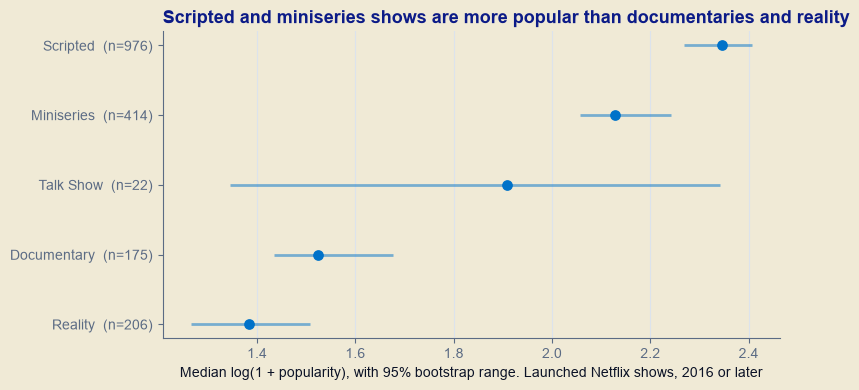

,n,median_log,lo,hi
type,,,,
Scripted,976,2.35,2.27,2.41
Miniseries,414,2.13,2.06,2.24
Talk Show,22,1.91,1.34,2.34
Documentary,175,1.52,1.43,1.68
Reality,206,1.38,1.27,1.51


In [17]:
recent = launched[launched.launch_year >= 2016].copy()

rng = np.random.default_rng(0)

def boot_ci(s, k=1000):
    s = s.to_numpy()
    meds = [np.median(rng.choice(s, len(s))) for _ in range(k)]
    return pd.Series({"lo": np.percentile(meds, 2.5), "hi": np.percentile(meds, 97.5)})

g = recent.groupby("type")
by_type_recent = g.agg(n=("id", "size"), median_log=("log_pop", "median"))
by_type_recent = by_type_recent.join(g.log_pop.apply(boot_ci).unstack())
by_type_recent = by_type_recent.sort_values("median_log")   # lowest first, so the top row is highest

y = np.arange(len(by_type_recent))
fig, ax = plt.subplots(figsize=(8, 4))

ax.hlines(y, by_type_recent.lo, by_type_recent.hi, color=BLUE, lw=2, alpha=0.5)
ax.scatter(by_type_recent.median_log, y, color=BLUE, s=45, zorder=3)

ax.set_yticks(y)
ax.set_yticklabels([f"{t}  (n={n})" for t, n in zip(by_type_recent.index, by_type_recent.n)])
ax.set_xlabel("Median log(1 + popularity), with 95% bootstrap range. Launched Netflix shows, 2016 or later")
ax.set_title("Scripted and miniseries shows are more popular than documentaries and reality")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../docs/popularity_by_type.png", dpi=150, bbox_inches="tight")   # for the slide, docs/ is git-ignored
plt.show()

by_type_recent.sort_values("median_log", ascending=False).round(2)


**Finding:**
- Two tiers: Scripted (2.35) and Miniseries (2.13) above Documentary (1.52) and Reality (1.38). The ranges do not overlap. Talk Show has 22 shows and a wide range, so no conclusion.
- The order is the same with all launch years included, so launch year does not explain it.
- **Caveat:** type may stand in for budget or marketing, which we do not have. Only launch year was checked.


## Genre

- A show can have several genres, so it counts in each one. Genres with 30 or more shows, shows from 2016 on.
- The 25th to 75th range is the spread of shows, not uncertainty.
- Second table: Scripted shows only, to see if a genre gap survives once type is held fixed.


In [18]:
genre = recent.explode("genres_list").dropna(subset=["genres_list"])

by_genre = genre.groupby("genres_list").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_genre = by_genre[by_genre.n >= 30].sort_values("median_log", ascending=False)
by_genre.round(2)


,n,median_log,q25,q75
genres_list,,,,
Sci-Fi & Fantasy,215,2.70,2.28,3.26
Action & Adventure,199,2.65,2.09,3.35
Mystery,184,2.60,2.07,3.25
Drama,687,2.48,1.91,3.11
Animation,268,2.44,1.99,3.14
Kids,134,2.31,1.72,3.01
Crime,276,2.24,1.77,2.77
Comedy,415,2.23,1.57,2.97
Family,95,2.20,1.61,3.03


In [19]:
scripted = recent[recent.type == "Scripted"]
genre_s = scripted.explode("genres_list").dropna(subset=["genres_list"])

by_genre_s = genre_s.groupby("genres_list").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_genre_s = by_genre_s[by_genre_s.n >= 30].sort_values("median_log", ascending=False)
by_genre_s.round(2)


,n,median_log,q25,q75
genres_list,,,,
Sci-Fi & Fantasy,182,2.74,2.30,3.32
Action & Adventure,168,2.69,2.14,3.40
Mystery,120,2.62,2.04,3.36
Drama,496,2.55,1.91,3.22
Crime,128,2.53,1.98,3.08
Animation,243,2.44,1.97,3.15
Kids,130,2.33,1.75,3.06
Comedy,328,2.32,1.66,3.03
Family,79,2.31,1.82,3.13


**Finding:**
- Across all types, Documentary (1.70) and Reality (1.37) are lowest, and Sci-Fi & Fantasy, Action & Adventure and Mystery are highest. This mostly repeats type: the Reality genre is 80% Reality type.
- Within Scripted the spread shrinks (Sci-Fi & Fantasy 2.74 down to Family 2.31) with heavy overlap. Genre adds little once type is fixed.
- Small lean toward Sci-Fi & Fantasy, Action & Adventure and Mystery, not tested with bootstrap ranges.


## Size and attention (Spearman)

- Spearman uses ranks, so skew and outliers do not matter. Shows from 2016 on, against `log_pop`.
- `vote_count` is an attention signal, like popularity, so it is a sanity check, not a driver.


In [20]:
num_cols = ["number_of_seasons", "number_of_episodes", "episode_run_time", "vote_count"]
corr = recent[num_cols + ["log_pop"]].corr(method="spearman")["log_pop"].drop("log_pop")
corr.round(2)


number_of_seasons     0.35
number_of_episodes    0.38
episode_run_time      0.05
vote_count            0.70
Name: log_pop, dtype: float64

**Finding:**
- `vote_count` 0.70, `number_of_episodes` 0.38, `number_of_seasons` 0.35, `episode_run_time` 0.05 (29% missing). Scripted only: seasons and episodes 0.43.
- Longer-running shows are more popular, probably because shows that do well get renewed (**assumed**). Known only after launch, so not pre-launch features.
- Run length could help rank shows already out there, not predict a new launch. How acquisitions are decided is **assumed**, not known.


## Country and language

- Both are known before launch. Shows from 2016 on, groups with 30 or more shows (a judgement call).
- Country (`origin_country_list`) is multi-label, so a show counts in each of its countries. Language (`original_language`) has one value per show.
- The 25th to 75th range is the spread of shows, not uncertainty.


In [21]:
# country (multi-label)
country = recent.explode("origin_country_list").dropna(subset=["origin_country_list"])
by_country = country.groupby("origin_country_list").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_country = by_country[by_country.n >= 30].sort_values("median_log", ascending=False)
print(by_country.round(2))

# original language (one value per show)
by_lang = recent.groupby("original_language").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_lang = by_lang[by_lang.n >= 30].sort_values("median_log", ascending=False)
by_lang.round(2)


                       n  median_log   q25   q75
origin_country_list                             
KR                    85        2.75  2.05  3.40
GB                   104        2.42  1.71  2.87
JP                   104        2.30  1.69  2.92
ES                    74        2.26  1.72  2.64
US                   730        2.22  1.58  2.91
IT                    36        2.16  1.41  2.54
MX                    59        2.09  1.61  2.87
FR                    45        2.06  1.60  2.39
DE                    38        2.05  1.52  2.63
BR                    55        1.55  1.12  2.17
IN                    73        1.52  1.15  1.99
TH                    37        1.40  1.12  1.98


,n,median_log,q25,q75
original_language,,,,
ko,84,2.78,2.03,3.41
ja,104,2.30,1.69,2.92
de,35,2.18,1.55,2.65
it,34,2.18,1.52,2.58
en,974,2.12,1.50,2.82
es,181,2.12,1.52,2.71
zh,38,2.05,1.52,2.57
fr,50,1.95,1.37,2.36
hi,54,1.61,1.18,2.15


### Is Korean really higher? A bootstrap test

- Language only (one value per show, so no show is counted twice).
- For each language the 95% bootstrap range of the median. For Korean against each other language, the range of the difference in medians.
- If that difference range excludes 0, the two are separated (`separated_from_ko` True).


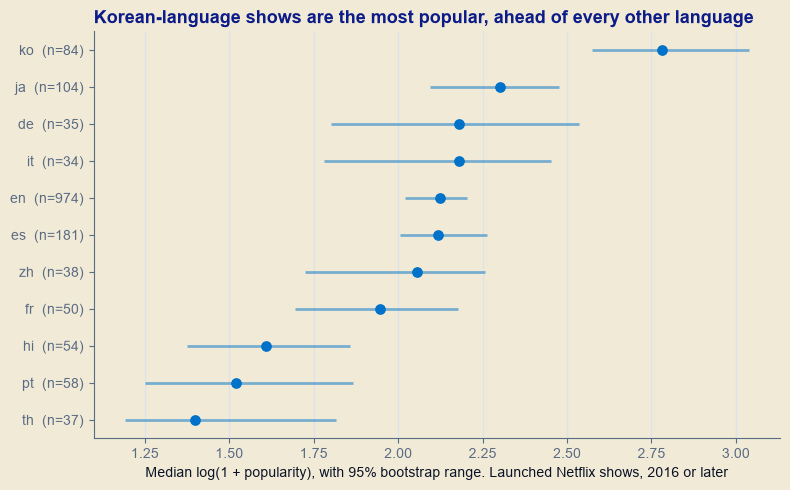

,n,median_log,lo,hi,ko_minus_this,diff_lo,diff_hi,separated_from_ko
language,,,,,,,,
th,37,1.40,1.19,1.82,1.33,0.88,1.68,True
pt,58,1.52,1.25,1.87,1.26,0.81,1.66,True
hi,54,1.61,1.37,1.86,1.17,0.83,1.53,True
fr,50,1.95,1.69,2.18,0.85,0.52,1.17,True
zh,38,2.05,1.72,2.26,0.79,0.41,1.18,True
es,181,2.12,2.01,2.26,0.65,0.37,0.92,True
en,974,2.12,2.02,2.20,0.67,0.42,0.94,True
it,34,2.18,1.78,2.45,0.65,0.22,1.09,True
de,35,2.18,1.80,2.54,0.61,0.21,1.08,True


In [22]:
def boot_median(s, k=1000):
    s = s.to_numpy()
    return np.array([np.median(rng.choice(s, len(s))) for _ in range(k)])

def lang_test(df, ref="ko", min_n=30):
    rng_local = np.random.default_rng(0)
    groups = {l: g.log_pop for l, g in df.groupby("original_language") if len(g) >= min_n}
    boots = {l: np.array([np.median(rng_local.choice(s.to_numpy(), len(s))) for _ in range(1000)])
             for l, s in groups.items()}
    rows = []
    for l, s in groups.items():
        diff = boots[ref] - boots[l] if l != ref else np.zeros(1000)
        rows.append({"language": l, "n": len(s), "median_log": s.median(),
                     "lo": np.percentile(boots[l], 2.5), "hi": np.percentile(boots[l], 97.5),
                     f"{ref}_minus_this": diff.mean(),
                     "diff_lo": np.percentile(diff, 2.5), "diff_hi": np.percentile(diff, 97.5)})
    out = pd.DataFrame(rows).set_index("language").sort_values("median_log")
    out["separated_from_ko"] = (out.diff_lo > 0) | (out.diff_hi < 0)
    return out

res = lang_test(recent)

y = np.arange(len(res))
fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(y, res.lo, res.hi, color=BLUE, lw=2, alpha=0.5)
ax.scatter(res.median_log, y, color=BLUE, s=45, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([f"{l}  (n={n})" for l, n in zip(res.index, res.n)])
ax.set_xlabel("Median log(1 + popularity), with 95% bootstrap range. Launched Netflix shows, 2016 or later")
ax.set_title("Korean-language shows are the most popular, ahead of every other language")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../docs/popularity_by_language.png", dpi=150, bbox_inches="tight")   # for the slide, docs/ is git-ignored
plt.show()

res.round(2)


In [23]:
# same test on Scripted shows only, to check type is not behind it
lang_test(recent[recent.type == "Scripted"]).round(2)


,n,median_log,lo,hi,ko_minus_this,diff_lo,diff_hi,separated_from_ko
language,,,,,,,,
th,35,1.39,1.19,1.70,1.52,1.10,1.91,True
hi,37,1.66,1.36,1.98,1.26,0.83,1.66,True
pt,31,1.84,1.49,2.16,1.10,0.63,1.59,True
es,95,2.39,2.22,2.62,0.55,0.19,0.95,True
ja,65,2.41,2.12,2.56,0.54,0.18,0.93,True
en,481,2.52,2.42,2.65,0.42,0.08,0.76,True
ko,48,2.91,2.63,3.26,0.00,0.00,0.00,False


**Finding:**
- Korean is the most popular language (median 2.78, range 2.57 to 3.04, 84 shows) and is separated from every other language, in all shows and in Scripted only (2.91, 48 shows). Korea is also top by country.
- English is fifth (2.12), almost tied with Spanish, Italian and German, so the middle order is noise. Its range is narrow (974 shows) because the median is well pinned down, not because English shows are alike.
- Thai (1.40), Portuguese (1.52) and Hindi (1.61) are lowest, in both runs.
- Country and language say the same thing, so one is enough as a feature. Both are known before launch.
- **Caveats:** 10 comparisons with no correction. **Assumed:** TMDB popularity reflects its own audience mix. Association only, and only noise from sample size is tested.


## Creators and production companies

- Both are known before launch and are multi-label (a show counts under each name). Shows from 2016 on.
- First check how often each name repeats, because a name seen once cannot be compared.
- Cut-offs (10 shows for companies, 4 for creators) are judgement calls. The 25th to 75th range is the spread of shows, not uncertainty.


In [24]:
def group_table(df, col, explode=False, min_n=30):
    d = df.explode(col).dropna(subset=[col]) if explode else df
    t = d.groupby(col).agg(
        n=("id", "size"),
        median_log=("log_pop", "median"),
        q25=("log_pop", lambda s: s.quantile(.25)),
        q75=("log_pop", lambda s: s.quantile(.75)),
    )
    return t[t.n >= min_n].sort_values("median_log", ascending=False).round(2)

# 1. coverage: how often does each name repeat?
for col in ["created_by_list", "production_companies_list"]:
    ex = recent.explode(col).dropna(subset=[col])
    counts = ex[col].value_counts()
    print(col, "| shows with a value:", recent[col].notna().sum(), "of", len(recent),
          "| distinct names:", len(counts),
          "| in 5+ shows:", (counts >= 5).sum(), "| in 10+:", (counts >= 10).sum())

# 2. names that repeat
print(group_table(recent, "production_companies_list", explode=True, min_n=10))
print(group_table(recent, "created_by_list", explode=True, min_n=4))

# 3. is a missing value itself a signal?
for col in ["created_by_list", "production_companies_list"]:
    print(col)
    print(recent.groupby(recent[col].notna()).log_pop.agg(["size", "median"]).round(2))


created_by_list | shows with a value: 983 of 1793 | distinct names: 1343 | in 5+ shows: 5 | in 10+: 0
production_companies_list | shows with a value: 1283 of 1793 | distinct names: 1383 | in 5+ shows: 48 | in 10+: 9


                                  n  median_log   q25   q75
production_companies_list                                  
Studio Dragon                    12        3.43  3.05  3.82
Warner Bros. Television          14        3.35  2.65  4.25
DreamWorks Animation Television  16        3.30  3.04  4.04
Netflix                          24        2.88  2.23  3.58
Universal Television             10        2.82  2.42  3.16
DreamWorks Animation             12        2.71  2.26  3.13
RadicalMedia                     11        2.35  2.05  2.52
Entertainment One                10        2.27  2.08  3.00
Boardwalk Pictures               12        1.59  1.26  2.15


                     n  median_log   q25   q75
created_by_list                               
Guillermo del Toro   4        3.45  3.04  4.12
Álex Pina            5        3.18  2.91  3.33
Mike Flanagan        5        3.14  3.08  3.40
Ryan Murphy          4        2.93  2.70  3.36
Ian Brennan          4        2.93  2.70  3.36
Carlos Montero       4        2.80  2.67  3.29
Ramón Campos         4        2.59  2.28  2.90
Manolo Caro          4        2.44  2.34  2.56
Joe Berlinger        5        2.43  2.36  2.61
Harlan Coben         5        2.39  2.26  2.60
Per-Olav Sørensen    4        2.27  2.10  2.39
George Kay           5        2.17  2.10  2.93
Jim Field Smith      4        2.13  2.09  2.36
Laura Gibson         4        1.96  1.55  2.38
Charlie Bennett      4        1.96  1.55  2.38
Bill Schultz         4        1.79  1.59  1.96
Jeff Borkin          4        1.79  1.59  1.96
Mary Bredin          4        1.79  1.59  1.96
Samuel Borkson       4        1.79  1.59  1.96
Arturo Sandov

**Finding:**
- Creators are too sparse to compare: 983 shows have one, 1,343 distinct names, only 5 names in 5 or more shows. Companies: 1,283 shows, 1,383 names, 48 in 5 or more, 9 in 10 or more.
- Top companies: Studio Dragon 3.43 (12 shows), Warner Bros. Television 3.35 (14), DreamWorks Animation Television 3.30 (16), Netflix 2.88 (24). Lowest: Boardwalk Pictures 1.59 (12). Small groups, no bootstrap range. Studio Dragon is Korean, so it probably repeats the language result.
- Missing is a strong signal: median 2.40 with a creator vs 1.68 without, 2.29 with a company vs 1.52 without. **Assumed:** better-known shows have fuller pages. We cannot tell if the page was filled in before launch or after the show got popular, so treat it with caution as a pre-launch feature.
- A name scan (all 2,031 shows) found few real variants: some company parents (DreamWorks, Gaumont, Entertainment One) and one creator pair. Most names are distinct, so the sparsity is real. The scan only catches similar-looking names. An alias or parent map is a next-time item.
- **Takeaway:** names are too sparse to be features. A has-a-value flag is stronger, but it is a data-completeness signal, not a cause.


## From EDA to the model

A bridge to the ML part of the talk. **Not a production model** (the brief does not ask for one). It is a sanity check: do the pre-launch columns carry any signal for a brand-new show?

- **Scope (decided):** new Netflix shows, predicted before launch. Acquired shows are out of scope. Launched 2016 to the snapshot date (1,793 shows). Target for now: `log_pop = log1p(popularity)`, not final.
- **Split by time, not at random:** train on 2016-2021 launches (1,174), test on 2022-2023 (606). 2024 is a partial year (13 shows) and is left out.
- **Run length does not carry over.** Episodes and seasons were the strongest EDA signal, but they only exist once a show has been renewed, so they are leakage for a new-show model. That is why run length is an acquisition argument, not a pre-launch feature.

| Column | Known before launch? | Used here? | Why |
|---|---|---|---|
| `type` | yes | yes | Set when the show is commissioned |
| `original_language` | yes | yes, top 12 plus "other" | Same |
| `genres` | yes | yes, one 0/1 column per genre | Tags can be edited after release (**assumed**) |
| `production_companies`, `created_by` | partly | only as `has_company` and `has_creator` flags | Names are too sparse (see above). The pages may be filled in after a show gets popular (**assumed**), so the flags are a leakage risk |
| `first_air_date` | yes | split only, not a feature | Used to cut train and test by launch year |
| `origin_country`, `languages`, `spoken_languages`, `production_countries` | yes | no | Overlap with `original_language` (**assumed**, not tested) |
| `name`, `overview`, `tagline` | yes | no | Text, not tried in this check |
| `number_of_episodes`, `number_of_seasons`, `episode_run_time`, `last_air_date`, `status`, `in_production` | **no** | no | Outcomes of renewal: they are known only after launch |
| `vote_average`, `vote_count` | **no** | no | Audience reaction after release |
| `popularity` | **no** | target only | The thing we predict |
| `homepage`, `poster_path`, `backdrop_path`, `adult` | not informative | no | `homepage` is already used to find Netflix shows. Artwork paths carry no signal by themselves |

In [ ]:
# Modelling set: Netflix shows launched 2016 to the snapshot date, split by launch year (no shuffling)
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

m = launched.copy()
m["launch_year"] = m.first_air_date.dt.year
m["log_pop"] = np.log1p(m.popularity)
m = m[m.launch_year >= 2016].copy()
has_any = lambda l: isinstance(l, list) and len(l) > 0           # a name is listed
m["has_company"] = m.production_companies_list.apply(has_any).astype(int)
m["has_creator"] = m.created_by_list.apply(has_any).astype(int)

train = m[m.launch_year <= 2021].copy()
test = m[m.launch_year.between(2022, 2023)].copy()                # 2024 is a partial year (13 shows), left out
top_lang = train.original_language.value_counts().head(12).index  # the 12 commonest languages in train, rest = "other"
for df in (m, train, test):
    df["lang"] = df.original_language.where(df.original_language.isin(top_lang), "other")

print(f"modelling set {len(m):,} | train 2016-2021 {len(train):,} | test 2022-2023 {len(test):,} | 2024 left out {(m.launch_year == 2024).sum()}")
print("missing type or language:", int(m.type.isna().sum()), int(m.original_language.isna().sum()))

### Recency check

The model is trained on older shows and tested on newer ones, so first check the EDA pattern still holds for recent launches. Median `log_pop` with a 95% bootstrap range of the median, 2016-22 vs 2023-24.

In [ ]:
# Recency check: does the EDA pattern hold for the newest launches? Median log_pop with 95% bootstrap range
rng_r = np.random.default_rng(0)

def boot_med(s, k=1000):
    a = s.to_numpy()
    meds = [np.median(rng_r.choice(a, len(a))) for _ in range(k)]
    return np.percentile(meds, [2.5, 97.5])

m["period"] = np.where(m.launch_year <= 2022, "2016-22", "2023-24")

def recency_table(col, min_n):
    rows = []
    for key, g in m.groupby(col):
        if min((g.period == p).sum() for p in ("2016-22", "2023-24")) < min_n:   # too few shows in one period
            continue
        row = {col: key}
        for p in ("2016-22", "2023-24"):
            s = g.loc[g.period == p, "log_pop"]
            lo, hi = boot_med(s)
            row[p] = f"{s.median():.2f} [{lo:.2f}, {hi:.2f}] n={len(s)}"
        rows.append(row)
    return pd.DataFrame(rows).set_index(col)

print("All shows, median log_pop:", m.groupby("period").log_pop.median().round(2).to_dict(), m.period.value_counts().to_dict())
print("\nBy type (groups under 3 shows in a period left out)")
display(recency_table("type", 3))
print("By original language (groups under 8 shows in a period left out)")
display(recency_table("original_language", 8))

**Finding:**
- Recent shows score higher overall: median 2.28 for 2023-24 (278 shows) vs 2.05 for 2016-22 (1,515). **Assumed:** TMDB popularity reflects current attention at the snapshot, so newer shows are favoured. Not tested.
- Type order holds in both periods: Scripted > Miniseries > Documentary > Reality (2023-24: 2.48, 2.39, 2.03, 1.58). In 2023-24 the Scripted and Miniseries ranges overlap, and Documentary has only 14 shows (range 1.56 to 2.87).
- Korean is top in both (2.66 with 63 shows, 3.40 with 21). The 2023-24 range (2.69 to 3.85) sits above the other languages' medians, but the groups are small. French, Italian and Portuguese have only 8 or 9 shows in 2023-24 and wide ranges, so read them as unclear.
- **Takeaway:** the pattern the model learns from 2016-21 is still there in the newest launches, with a higher level. This is a check on medians, not a test of the model.

### Baseline vs model

- **Baselines:** the training median by type, and by type x language (falls back to the type median for a pair not seen in training). These are the rules the EDA would suggest.
- **Models:** Ridge, and gradient boosting (`HistGradientBoostingRegressor`, max_depth 3, learning rate 0.05, 300 iterations, seed 0), on `type`, language, genres, `has_company`, `has_creator`. No tuning. Boosting is also run without the two flags.
- **Metrics:** Spearman (does it rank shows in the right order?) and precision in the top 10%: of the 61 shows it ranks highest, how many are really in the top 10%. Random picking gives about 0.10. Ties are broken at random, so a rule with few groups is not flattered.
- **Ranges:** 95% bootstrap over the test shows (1,000 resamples). They cover test-set luck only, not training variability.

In [ ]:
# Baseline vs model on the time split. Pre-launch features only.
genres = sorted({g for l in train.genres_list if isinstance(l, list) for g in l})

def features(df, flags=True):
    parts = [pd.get_dummies(df.type).astype(int), pd.get_dummies(df.lang).astype(int),
             pd.DataFrame({f"genre_{g}": df.genres_list.apply(lambda l: int(isinstance(l, list) and g in l)) for g in genres}, index=df.index)]
    if flags:
        parts.append(df[["has_company", "has_creator"]])
    return pd.concat(parts, axis=1)

def aligned(flags):
    cols = features(train, flags).columns                           # test gets the same columns, missing ones are 0
    return features(train, flags), features(test, flags).reindex(columns=cols, fill_value=0)

def top10_precision(y, p, draws=200, seed=0):
    """Share of the predicted top 10% that really are in the top 10%. Ties broken at random (averaged), so a rule with few groups is not flattered."""
    r = np.random.default_rng(seed); k = round(len(y) * 0.10)
    actual = set(np.argsort(-y)[:k])
    return np.mean([len(actual & set(np.lexsort((r.random(len(y)), -p))[:k])) / k for _ in range(draws)])

y = test.log_pop.to_numpy()
med_type = train.groupby("type").log_pop.median()
med_tl = train.groupby(["type", "lang"]).log_pop.median()
p_type = test.type.map(med_type).fillna(train.log_pop.median()).to_numpy()
p_tl = np.array([med_tl.get((t, l), np.nan) for t, l in zip(test.type, test.lang)])
p_tl = np.where(np.isnan(p_tl), p_type, p_tl)                       # unseen type x language pair falls back to the type median

Xtr, Xte = aligned(True); Xtr0, Xte0 = aligned(False)
hgb = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0)
preds = {
    "Median by type": p_type,
    "Median by type x language\n(baseline)": p_tl,
    "Ridge": Ridge(alpha=1.0).fit(Xtr, train.log_pop).predict(Xte),
    "Boosting": hgb().fit(Xtr, train.log_pop).predict(Xte),
    "Boosting without\ncompany and creator flags": hgb().fit(Xtr0, train.log_pop).predict(Xte0),
}
BASE = "Median by type x language\n(baseline)"

# 95% range from resampling the test shows (this covers test-set luck only, not training variability)
rng_m = np.random.default_rng(0)
idx = [rng_m.integers(0, len(y), len(y)) for _ in range(1000)]
rho = lambda p, i: spearmanr(y[i], p[i])[0]
res = pd.DataFrame({
    "spearman": {k: spearmanr(y, p)[0] for k, p in preds.items()},
    "lo": {k: np.percentile([rho(p, i) for i in idx], 2.5) for k, p in preds.items()},
    "hi": {k: np.percentile([rho(p, i) for i in idx], 97.5) for k, p in preds.items()},
    "top10_precision": {k: top10_precision(y, p) for k, p in preds.items()},
})
# paired: same resampled shows for model and baseline, so the gap is not hidden by shared test-set luck
gap = {k: np.percentile([rho(p, i) - rho(preds[BASE], i) for i in idx], [2.5, 97.5]) for k, p in preds.items() if k != BASE}
res.index = [k.replace("\n", " ") for k in res.index]
print(f"test shows {len(y)} | random picking would give about 0.10 precision")
display(res.round(2))
for k, (lo, hi) in gap.items():
    print(f"gap to baseline, {k.replace(chr(10), ' ')}: {res.loc[k.replace(chr(10), ' '), 'spearman'] - res.loc[BASE.replace(chr(10), ' '), 'spearman']:+.2f} [{lo:+.2f}, {hi:+.2f}]")

# chart: Spearman by model, baseline highlighted
fig, ax = plt.subplots(figsize=(9, 4.8))
names = list(preds)[::-1]; ypos = np.arange(len(names))
vals = np.array([spearmanr(y, preds[k])[0] for k in names])
lo = np.array([res.loc[k.replace("\n", " "), "lo"] for k in names]); hi = np.array([res.loc[k.replace("\n", " "), "hi"] for k in names])
ax.barh(ypos, vals, height=0.6, color=[BLUE if k == BASE else OTHER for k in names])
ax.errorbar(vals, ypos, xerr=[vals - lo, hi - vals], fmt="none", ecolor=INK, elinewidth=1.2, capsize=3)
for yy, v, h in zip(ypos, vals, hi):
    ax.text(h + 0.015, yy, f"{v:.2f}", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(ypos); ax.set_yticklabels(names); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 0.8); ax.set_xlabel("Spearman correlation with actual popularity, 2022-2023 launches (bars show the 95% bootstrap range)")
ax.set_title("Pre-launch features rank new Netflix shows better than a type and language rule")
fig.text(0.01, 0.01, f"Netflix shows launched 2016-2021 train, 2022-2023 test ({len(y)} shows). Highlighted bar is the baseline. One split, no tuning.", fontsize=7.5, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("../docs/ml_sanity_check_spearman.png", dpi=150)
plt.show()

**Findings and caveats:**
- Pre-launch columns carry signal: Spearman 0.56 for Ridge and for boosting on 2022-23 launches, against 0.42 for the type x language median and 0.30 for type alone. Paired bootstrap of the gap to the baseline: Ridge +0.15 (+0.09 to +0.21). This is an association, not a cause.
- About one in three of the predicted top 10% really is in the top 10% (0.33 for Ridge, 0.32 for boosting, vs 0.25 for the baseline and about 0.10 by chance).
- Ridge and boosting tie, so the signal looks mostly additive (**assumed**: no gain from interactions at this size).
- The company and creator flags are the weak point. Dropping them takes boosting from 0.56 to 0.51 (precision 0.32 to 0.27). They may be filled in after a show gets popular (**assumed**), so 0.51 is the safer number.
- The target includes a recency effect (2023-24 sits higher), so a real version should score a show within its launch year, for example as a percentile (**assumed** to help, not tested).
- Limits: one split, no tuning, 606 test shows, Netflix only. Popularity is a TMDB score taken at one snapshot, not at launch, so older shows had longer to build it. No cast, budget, marketing or viewing data.

### Synopsis: embeddings vs sentiment

- `overview` is the only rich pre-launch text. Two NLP views of it:
  - **Sentiment** (VADER, rule-based): one number per synopsis, -1 dark to +1 upbeat.
  - **Embeddings** (`all-MiniLM-L6-v2`, a small pretrained transformer): 384 numbers per synopsis, close numbers mean similar plots.
- The map squeezes the 384 numbers to 2D with t-SNE, **for display only**. Gaps between clusters are not real distances.
- Embeddings as a feature: Ridge on the 20 main directions (PCA fitted on train only), same time split as above.
- Needs `uv add sentence-transformers vaderSentiment` once. The model downloads on first run (about 90 MB).
- Groups: Scripted and Miniseries as Fiction, Documentary, Reality. Talk Show and News in grey.

In [ ]:
# Synopsis: embeddings vs sentiment (launched Netflix shows from 2016 with an overview)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

syn = m[m.overview.notna()].copy()
E = SentenceTransformer("all-MiniLM-L6-v2").encode(syn.overview.tolist(), batch_size=64, show_progress_bar=False)
sia = SentimentIntensityAnalyzer()
syn["sent"] = syn.overview.apply(lambda t: sia.polarity_scores(t)["compound"])
xy = TSNE(2, random_state=0, init="pca", perplexity=30).fit_transform(E)
syn["x"], syn["y"] = xy[:, 0], xy[:, 1]
syn["grp"] = syn.type.map({"Scripted": "Fiction", "Miniseries": "Fiction", "Documentary": "Documentary", "Reality": "Reality"}).fillna("Other")

# embeddings as the only feature: Ridge on 20 PCA directions, PCA fitted on train years only
is_tr = syn.launch_year.le(2021).to_numpy(); is_te = syn.launch_year.between(2022, 2023).to_numpy()
pca = PCA(20, random_state=0).fit(E[is_tr]); P = pca.transform(E)
p_emb = Ridge(alpha=1.0).fit(P[is_tr], syn.log_pop[is_tr]).predict(P[is_te])
rho_emb = spearmanr(syn.log_pop[is_te], p_emb)[0]
rho_sent = spearmanr(syn.sent, syn.log_pop)[0]
print(f"shows {len(syn):,} | embeddings-only Ridge on 2022-23: Spearman {rho_emb:.2f} | sentiment vs log_pop: Spearman {rho_sent:.2f}")
display(syn.groupby("grp").sent.agg(["median", "size"]).round(2))

# chart. Categorical colours checked with the dataviz validator on cream (all pairs pass, orange needs labels: legend + row names)
COL = {"Fiction": BLUE, "Reality": "#E6007E", "Documentary": "#FF8A00", "Other": "#B8B2A0"}
order = ["Fiction", "Reality", "Documentary"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.33, 6.4), gridspec_kw={"width_ratios": [1.35, 1]})
for a in (a1, a2):
    for s in a.spines.values(): s.set_visible(False)

o = syn[syn.grp == "Other"]
a1.scatter(o.x, o.y, s=10, c=COL["Other"], lw=0)
for g in order:
    d = syn[syn.grp == g]
    a1.scatter(d.x, d.y, s=12, c=COL[g], lw=0.4, edgecolors=SURFACE, label=f"{g} ({len(d):,})")
a1.set_xticks([]); a1.set_yticks([]); a1.grid(False)
a1.set_title("Synopsis embeddings: each dot is a show, close dots have similar plots", fontsize=11, color=INK, fontweight="normal")
near = ["Squid Game", "Surviving Paradise", "The Mole", "The Circle Brazil", "Squid Game: The Challenge"]
lab = syn[syn.name.isin(near)].drop_duplicates("name")
a1.scatter(lab.x, lab.y, s=60, facecolors="none", edgecolors=INK, lw=1.2, zorder=5)
sq = lab[lab.name == "Squid Game"].iloc[0]
a1.annotate("Squid Game and its nearest plots:\nThe Mole, The Circle Brazil,\nSurviving Paradise, Squid Game: The Challenge",
            xy=(sq.x, sq.y), xytext=(0.02, 0.03), textcoords="axes fraction", fontsize=9, color=INK,
            bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec=MUTED, lw=0.6), arrowprops=dict(arrowstyle="-", color=INK, lw=0.8))
a1.legend(loc="upper left", fontsize=9, markerscale=1.8, handletextpad=0.3)

r = np.random.default_rng(0)
for i, g in enumerate(order):
    d = syn[syn.grp == g]
    a2.scatter(d.sent, i + r.uniform(-0.28, 0.28, len(d)), s=8, c=COL[g], alpha=0.55, lw=0)
    med = d.sent.median()
    a2.plot([med, med], [i - 0.36, i + 0.36], color=INK, lw=2)
    a2.text(med, i - 0.40, f"median {med:+.2f}", ha="center", va="bottom", fontsize=9, color=INK,
            bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec="none"))
a2.set_yticks(range(len(order)), order, fontsize=10, color=INK)
a2.set_ylim(-0.75, len(order) - 0.5); a2.invert_yaxis()
a2.set_xlim(-1.05, 1.05); a2.set_xticks([-1, -0.5, 0, 0.5, 1]); a2.tick_params(length=0)
a2.set_xlabel("VADER sentiment of the synopsis (-1 dark, +1 upbeat)", fontsize=9, color=MUTED)
a2.set_title("Sentiment: one number per show, groups overlap heavily", fontsize=11, color=INK, fontweight="normal")

fig.suptitle("Embeddings capture what a show is about, sentiment only how dark it sounds",
             x=0.012, ha="left", fontsize=17, fontweight="bold", color=TITLE, y=0.975)
fig.text(0.012, 0.015, f"Launched Netflix shows from 2016 with a synopsis ({len(syn):,}). Map: all-MiniLM-L6-v2 embeddings squeezed to 2D with t-SNE (display only). "
         f"Ridge on embeddings alone: Spearman {rho_emb:.2f} on 2022-23 shows. Sentiment vs popularity: Spearman {rho_sent:.2f}.", fontsize=8.5, color=MUTED)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
fig.savefig("../docs/synopsis_embedding_vs_sentiment.png", dpi=200)
plt.show()

**Finding:**
- **Embeddings group shows by what they are about.** Reality and documentary sit together on one side of the map, fiction spreads over the rest. Squid Game sits next to The Mole and The Circle Brazil (survival and competition), a finer theme than any genre label.
- **Sentiment is one dimension.** Fiction covers the whole range, Reality leans upbeat (median +0.60), and the groups overlap. Earlier test: it adds nothing beyond genre.
- **As a feature:** embeddings alone rank 2022-23 shows about as well as the type x language baseline. On top of the tabular columns they add little (about +0.01 to +0.02 in a quick check outside the notebook, **assumed** to hold), because they mostly repeat type and genre.
- **Use beyond prediction:** finer categories for the catalogue (the brief: "inform how we categorise shows"), for example clustering into sub-genres.
- **Caveats:** the model reads English best, and some synopses may not be English (**assumed**, not checked). Synopses may be edited after launch (**assumed**). One split, no tuning.